[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/exercises/solutions/ex_06_water_quality_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🌊 Solutions: Water quality & inland/coastal water intelligence
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Build a water-quality analysis the careful way — masks first, then indices, then a critical look at what else could cause the signal. Your test sites are the clear, shallow Gulf waters of the Al Dhafra coast (UAE) and the turbid mangrove estuary of Jiquilisco Bay (El Salvador).

These exercises accompany the theme notebook [`06_ecosystem_health_water_qualityy.ipynb`](../https://github.com/Tnecniv-Teikram/813-hyperspectral-hackathon/blob/main/06_ecosystem_health_water_qualityy.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Checking quality masks (false cloud flags over bright sabkha)
- Choosing a water mask (NDWI vs MNDWI) for the task at hand
- Computing the Floating Algae Index and recognising its false positives
- Comparing water bodies with water-masked NDCI and turbidity proxies
- Recognising bottom reflectance in optically shallow water
- What a calibrated water-quality service needs

**Data**
- `20250511_074311_00_4001` — Al Dhafra coast, Abu Dhabi, UAE (11 May 2025)
- `20250223_165546_32_4001` — Jiquilisco Bay, El Salvador (23 Feb 2025), for comparison

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20250511_074311_00_4001  (Al Dhafra coast, UAE)
File       : /home/course/notebooks/20250511_074311_00_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 733 rows × 878 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32639, 30 m pixels
No-data    : 21.3%   cloud flag: 40.4%   cirrus flag: 0.0%   usable: 38.4%


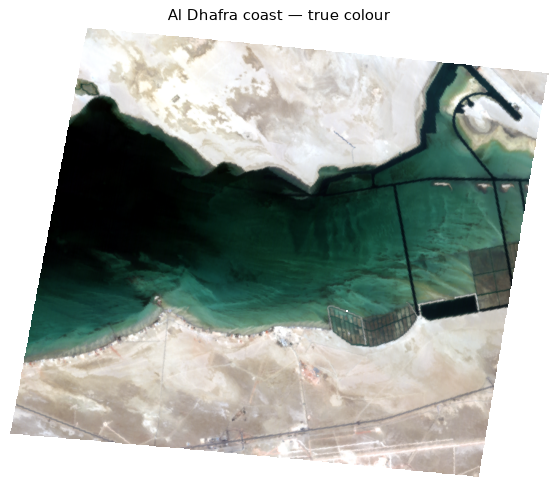

In [2]:
UAE_ID = "20250511_074311_00_4001"   # Al Dhafra coast, Abu Dhabi, UAE — the first scene of notebook 06
ES_ID = "20250223_165546_32_4001"    # Jiquilisco Bay estuary, El Salvador — for comparison

uae = hu.get_scene(UAE_ID)
print(uae.summary())

# Read the bands WITHOUT the cloud mask (cloud=False) — Exercise 1 shows why.
valid = uae.valid_mask(cloud=False)
B = {w: uae.read_band(w, cloud=False) for w in (443, 490, 560, 645, 665, 708, 859, 1240, 1650)}
NDWI = hu.nd(B[560], B[859])
water = valid & (NDWI > 0)          # the water mask used throughout
PIXEL_KM2 = 0.0009

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(uae.rgb(mask=True)); ax.set_title("Al Dhafra coast — true colour"); ax.axis("off")
plt.show()

## Exercise 1 — The '40% cloud' scene without a cloud in the sky  ⭐

`scene.summary()` reports that about 40% of this scene is flagged as cloud, yet the true-colour image shows a
clear sky.

1. Overlay the `beta_cloud_mask` on the true-colour image.
2. What fraction of the flagged pixels lies on land (NDWI ≤ 0) and what fraction on water? What share of all
   land pixels is flagged?
3. What do you conclude about using the default `valid_mask()` for this scene, and what does that mean for any
   automatic "cloud < 10%" scene filter in a product?

### Solution

flagged as cloud: 51.2% of valid pixels
  of the flagged pixels: 100.0% on land, 0.02% on water
  share of all land pixels flagged: 94.8%


catalogue cloud_percent for this scene: 51


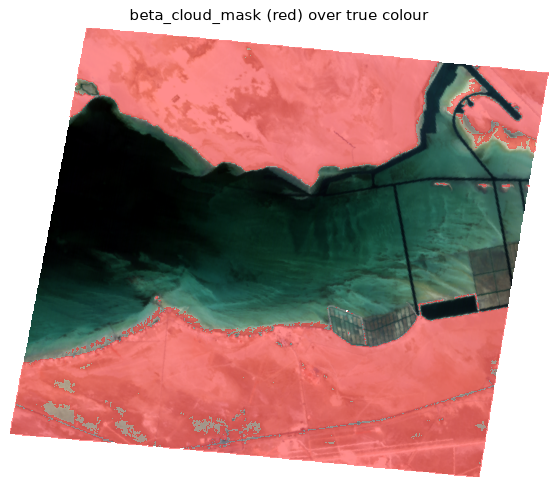

In [3]:
cloud = uae.masks()["cloud"] & valid
land = valid & (NDWI <= 0)
print(f"flagged as cloud: {cloud.sum() / valid.sum():.1%} of valid pixels")
print(f"  of the flagged pixels: {(cloud & land).sum() / cloud.sum():.1%} on land, {(cloud & water).sum() / cloud.sum():.2%} on water")
print(f"  share of all land pixels flagged: {(cloud & land).sum() / land.sum():.1%}")
idx = hu.load_catalog_index()
print("catalogue cloud_percent for this scene:", idx.loc[idx.id == UAE_ID, "cloud_percent"].iloc[0])

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(uae.rgb(mask=True))
ax.imshow(np.where(cloud, 1, np.nan), cmap="autumn", alpha=0.45, interpolation="nearest")
ax.set_title("beta_cloud_mask (red) over true colour"); ax.axis("off")
plt.show()

**Interpretation:** almost all flagged pixels are **on land** — practically all of the bright sabkha (salt flat)
and desert — and virtually none on the water. The beta cloud mask confuses very bright, white surfaces
with clouds, a well-known problem in arid regions and over snow, salt and white roofs. The catalogue entry says
0% cloud, so the two sources disagree.

For a water-quality product the false flags do no harm, but for land analyses in the Gulf region the default
`valid_mask()` would silently delete the salt flats. **Always look at your masks**, use `cloud=False` where
they are clearly wrong, and never trust an automatic "cloud < 10%" filter without checking what it filters.

## Exercise 2 — Water mask first: NDWI or MNDWI?  ⭐

Every water-quality analysis starts with a water mask.

1. Compute the water area (km²) with NDWI = (G − NIR) / (G + NIR) > 0 and with MNDWI = (G − SWIR₁₆₅₀) /
   (G + SWIR₁₆₅₀) > 0.
2. Map the pixels where the two masks disagree. Where are they?
3. Which mask would you use here, and why?

### Solution

NDWI  > 0:   210.9 km²
MNDWI > 0:   221.4 km²
disagreement: 11,855 px (2.3% of valid pixels)


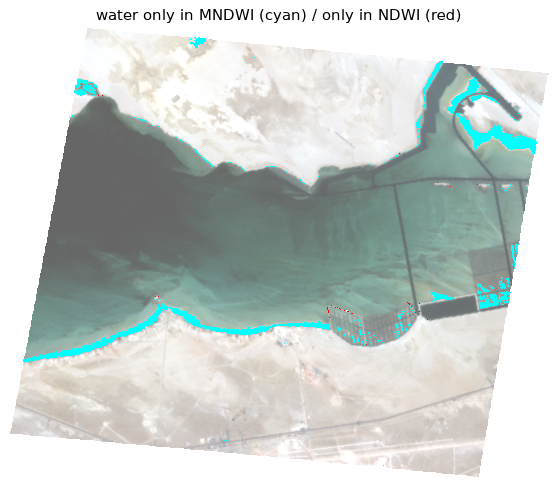

In [4]:
MNDWI = hu.nd(B[560], B[1650])
ndwi_mask, mndwi_mask = valid & (NDWI > 0), valid & (MNDWI > 0)
print(f"NDWI  > 0: {ndwi_mask.sum() * PIXEL_KM2:7.1f} km²")
print(f"MNDWI > 0: {mndwi_mask.sum() * PIXEL_KM2:7.1f} km²")
diff = ndwi_mask != mndwi_mask
print(f"disagreement: {diff.sum():,} px ({diff[valid].mean():.1%} of valid pixels)")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(uae.rgb(mask=True), alpha=0.6)
ax.imshow(np.where(mndwi_mask & ~ndwi_mask, 1, np.nan), cmap="cool", interpolation="nearest")
ax.imshow(np.where(ndwi_mask & ~mndwi_mask, 1, np.nan), cmap="autumn", interpolation="nearest")
ax.set_title("water only in MNDWI (cyan) / only in NDWI (red)"); ax.axis("off")
plt.show()

**Interpretation:** both masks agree on the open water. MNDWI is slightly larger: it adds a fringe of pixels
along the shorelines, intertidal flats, wet sabkha and the salt ponds, where a thin water film or wet salt
crust is dark in the SWIR but still bright in the NIR. For open-water quality, the stricter NDWI mask (or even
an eroded mask a couple of pixels away from the shore) is safer, because shoreline pixels mix land and water
and ruin water-quality indices. For flood or wetland extent, MNDWI is the better choice.

## Exercise 3 — Floating Algae Index (FAI)  ⭐⭐

The **Floating Algae Index** (Hu, 2009) measures how far the NIR reflectance rises above a straight baseline
drawn between red and SWIR:

$$\mathrm{FAI} = R_{859} - \left[R_{645} + (R_{1240} - R_{645})\,\frac{859 - 645}{1240 - 645}\right]$$

Floating vegetation (Sargassum, algal scums, water hyacinth) has a strong NIR peak, so FAI > 0, while clear water
stays near or below 0. The baseline makes FAI fairly robust to haze and glint.

1. Compute FAI over the water mask and map it with a stretch from its 1st to 99.5th percentile.
2. Show the true-colour image of the pixels with the highest FAI (top 0.1%). What are they?

### Solution

FAI over water: median -0.0223, 99.9th pct +0.0359; 235 top pixels


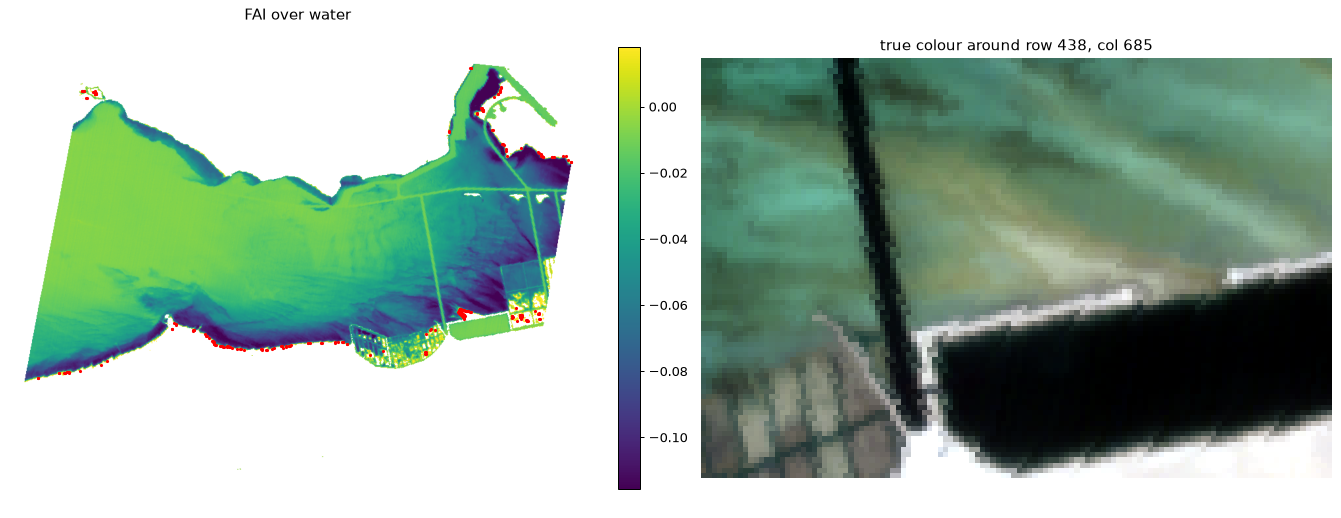

In [5]:
FAI = B[859] - (B[645] + (B[1240] - B[645]) * (859 - 645) / (1240 - 645))
FAI_w = np.where(water, FAI, np.nan)
lo, hi = np.nanpercentile(FAI_w, [1, 99.5])
top = water & (FAI > np.nanpercentile(FAI[water], 99.9))
print(f"FAI over water: median {np.nanmedian(FAI_w):+.4f}, 99.9th pct {np.nanpercentile(FAI[water], 99.9):+.4f}; {top.sum()} top pixels")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
im = axes[0].imshow(FAI_w, cmap="viridis", vmin=lo, vmax=hi); axes[0].set_title("FAI over water")
plt.colorbar(im, ax=axes[0], fraction=0.035)
rr, cc = np.nonzero(top)
axes[0].plot(cc, rr, "r.", ms=3)
axes[0].axis("off")
# zoom on the largest cluster of top pixels
r, c = int(np.median(rr)), int(np.median(cc))
axes[1].imshow(uae.rgb(window=(r - 40, r + 40, c - 60, c + 60)))
axes[1].set_title(f"true colour around row {r}, col {c}"); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Interpretation:** over most of the Gulf, FAI is slightly negative — clear water with no floating material.
The highest values (red dots) are not algae blooms: they sit on **shoreline and pond-edge pixels**, **man-made
structures** (causeways, the port, ships) and the **shallow, bright-bottomed** margins, where the seafloor or
land adds NIR reflectance. That is the typical false-positive list of FAI, which is why operational Sargassum
products remove shoreline pixels, mask ships, and require spatial and temporal consistency. A genuine floating
algae mat would show a vegetation-like spectrum (red edge + NIR plateau) within otherwise dark water.

## Exercise 4 — Chlorophyll and turbidity: Gulf vs estuary  ⭐⭐

Compute the water-masked NDCI (R₇₀₈ vs R₆₆₅) and the turbidity proxy (R₆₆₅ vs R₅₆₀) for the Al Dhafra scene and
for the El Salvador estuary scene (use NDWI > 0.1 there). Compare the distributions with histograms and report
their medians. What does the difference tell you about the two water bodies?

### Solution

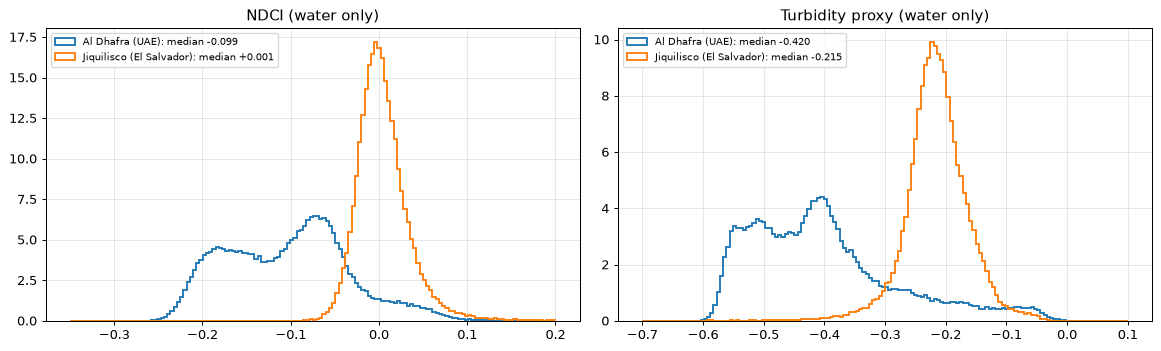

In [6]:
es = hu.get_scene(ES_ID)
es_valid = es.valid_mask()
E = {w: es.read_band(w) for w in (560, 665, 708, 859)}
es_water = es_valid & (hu.nd(E[560], E[859]) > 0.1)

sets = {"Al Dhafra (UAE)": (hu.nd(B[708], B[665])[water], hu.nd(B[665], B[560])[water]),
        "Jiquilisco (El Salvador)": (hu.nd(E[708], E[665])[es_water], hu.nd(E[665], E[560])[es_water])}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (ndci, turb) in sets.items():
    axes[0].hist(ndci, bins=150, range=(-0.35, 0.2), histtype="step", density=True, lw=1.5, label=f"{name}: median {np.nanmedian(ndci):+.3f}")
    axes[1].hist(turb, bins=150, range=(-0.7, 0.1), histtype="step", density=True, lw=1.5, label=f"{name}: median {np.nanmedian(turb):+.3f}")
axes[0].set_title("NDCI (water only)"); axes[1].set_title("Turbidity proxy (water only)")
for a in axes: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation:** the Gulf water has clearly lower NDCI and a much more negative turbidity proxy. It is
**clear, oligotrophic water**, where the green reflectance dominates the red. The El Salvador estuary has more
red and red-edge reflectance, as expected from a sediment-laden, nutrient-rich estuary fed by rivers and
mangroves.

The *relative* comparison is meaningful. The absolute values, however, are not chlorophyll or sediment
concentrations: the scenes differ in atmosphere, sun angle and bottom visibility (next exercise), and the
proxies were never calibrated with water samples.

## Exercise 5 — Shallow water: when you see the seafloor, not the water  ⭐⭐⭐

Much of the Al Dhafra coast is shallow, with bright sand and seagrass beds. Light reflected by the **bottom**
adds to the water signal.

1. Extract a north–south transect along column 300, from row 190 to row 475 (water pixels only). Plot the
   reflectance at 443, 560, 665 and 708 nm, and the NDCI and turbidity proxies along it.
2. Compare the mean spectra of "bright" water (R₅₆₀ above the 80th percentile of the water pixels) and "dark"
   water (below the 20th percentile).
3. Explain why NDCI and turbidity rise near the shores. How would you avoid misinterpreting this as algae or
   sediment?

### Solution

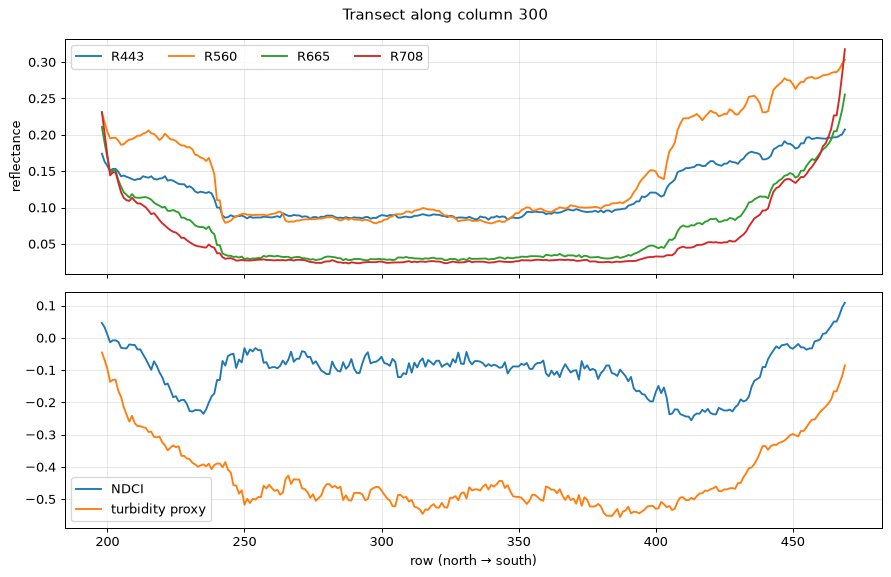

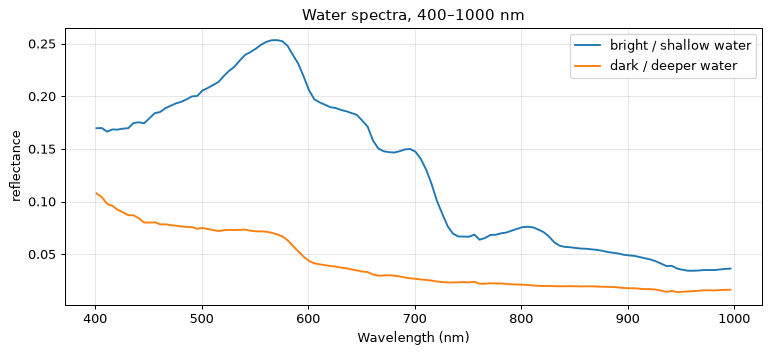

In [7]:
rows = np.arange(190, 476); col = 300
on_water = water[rows, col]
NDCI_u = hu.nd(B[708], B[665]); TURB_u = hu.nd(B[665], B[560])

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for w in (443, 560, 665, 708):
    axes[0].plot(rows, np.where(on_water, B[w][rows, col], np.nan), label=f"R{w}")
axes[0].set_ylabel("reflectance"); axes[0].legend(ncol=4); axes[0].grid(alpha=0.3)
axes[1].plot(rows, np.where(on_water, NDCI_u[rows, col], np.nan), label="NDCI")
axes[1].plot(rows, np.where(on_water, TURB_u[rows, col], np.nan), label="turbidity proxy")
axes[1].set_xlabel("row (north → south)"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.suptitle("Transect along column 300"); plt.tight_layout(); plt.show()

def mean_spec(mask, n=400):
    rr, cc = np.nonzero(mask)
    pick = np.random.default_rng(0).choice(len(rr), size=min(n, len(rr)), replace=False)
    rr, cc = rr[pick], cc[pick]
    cube, wl = uae.read_cube((rr.min(), rr.max() + 1, cc.min(), cc.max() + 1), cloud=False)
    return np.nanmean(cube[:, rr - rr.min(), cc - cc.min()], axis=1), wl

g = B[560]
bright = water & (g > np.nanpercentile(g[water], 80))
dark = water & (g < np.nanpercentile(g[water], 20))
fig, ax = plt.subplots(figsize=(10, 4))
for name, m in (("bright / shallow water", bright), ("dark / deeper water", dark)):
    spec, wl = mean_spec(m)
    sel = wl < 1000
    ax.plot(wl[sel], spec[sel], label=name)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("reflectance"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Water spectra, 400–1000 nm")
plt.show()

**Interpretation**
- In the **deep channel** (middle of the transect), the reflectance is low and flat, and it is almost zero in
  the red and red edge.
- Towards both shores all visible bands rise, the longer wavelengths (665, 708 nm) proportionally more,
  because in shallow water less water sits between the sensor and the bright sand. As a result, NDCI and the
  turbidity proxy **increase near the shores without any change in chlorophyll or sediment**.
- The bright-water spectrum is much brighter across 450–700 nm and keeps a clear signal into the red edge.
  That is the signature of **bottom reflectance**. Dips in NDCI over the transition zones mark darker bottom
  types (seagrass beds).

To avoid misinterpretation:
- Mask **optically shallow** water with a bathymetry map (e.g. GEBCO or nautical charts) or with a
  bottom-visibility criterion.
- Use physics-based inversions that model depth and bottom albedo explicitly (e.g. Lee et al., 1999).
- Validate against in-situ samples taken in both deep and shallow areas.

The same effect is an **opportunity**: shallow-water bathymetry and benthic habitat (seagrass, coral) mapping
are strong hyperspectral applications.

## Exercise 6 — Reflection — from proxy maps to a water-quality service  ⭐

A water authority wants a monthly chlorophyll-a map (mg m⁻³) of this coast. In a short markdown cell, list
what you need beyond the NDCI map: the in-situ data (what, where, when), how to match satellite and field
measurements, and which conditions you would flag as "unreliable" in the product.

### Solution

**Model answer**
- **In-situ data:** water samples analysed for chlorophyll-a (HPLC or fluorometry), total suspended solids
  (TSS) and CDOM absorption, plus Secchi depth and water depth at each station. Cover the range of conditions
  (clear and turbid, deep and shallow, bloom and no bloom) over several seasons. Continuous buoys with
  fluorescence sensors help to fill the gaps in time.
- **Matchups:** field samples within about ±3 hours of the overpass (tides and currents move water quickly),
  compared with the median of a 3×3 pixel window in homogeneous water. Reject windows with a high variance, and
  keep a separate set of matchups for validation (RMSE, bias and R² in log space for chlorophyll).
- **Model:** calibrate NDCI or a band-ratio or physics-based algorithm on the matchups. Hyperspectral data
  also allow semi-analytical inversions that retrieve chlorophyll, sediment and CDOM jointly.
- **Quality flags:** optically shallow water, pixels within 1–2 pixels of land (adjacency and mixing), sun
  glint, residual haze (a high SWIR signal over water), floating material or ships (high FAI), cloud and
  cloud shadow, and values outside the calibration range. Deliver the flags with every map.
- **Continuity:** Tanager is a tasked, single-satellite mission, so a monthly service needs a tasking plan or
  gap-filling with multispectral sensors (Sentinel-2/3) calibrated against the hyperspectral product.

## Key takeaways

- Inspect masks before trusting them — the beta cloud mask flags bright salt flats as cloud.
- Mask water first, and keep away from shorelines for water-quality indices.
- FAI highlights anything with a NIR peak: ships, structures and mixed shoreline pixels as well as algae.
- In shallow water, the seafloor raises red and red-edge reflectance and mimics chlorophyll or sediment.
- Quantitative water quality needs in-situ matchups, calibration and quality flags.

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC